In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os, sys
os.chdir('/content/drive/MyDrive/network-intrusion-ml')
sys.path.append('/content/drive/MyDrive/network-intrusion-ml')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.utils import PROCESSED_DIR, FIG_DIR, save_fig, save_table, RANDOM_STATE

sns.set_theme(style="whitegrid")

df = pd.read_parquet(PROCESSED_DIR / "cicids2017_clean.parquet")

# Temporary column for EDA only (BENIGN vs ATTACK). Not saved to the file.
df["Binary"] = np.where(df["Label"] == "BENIGN", "BENIGN", "ATTACK")

feature_cols = [c for c in df.columns if c not in ("Label", "Label_Group", "Binary")]
print("Rows:", f"{len(df):,}", "| Feature columns:", len(feature_cols))

Mounted at /content/drive
Rows: 2,497,980 | Feature columns: 69


[saved figure] /content/drive/MyDrive/network-intrusion-ml/results/figures/02_class_distribution.png


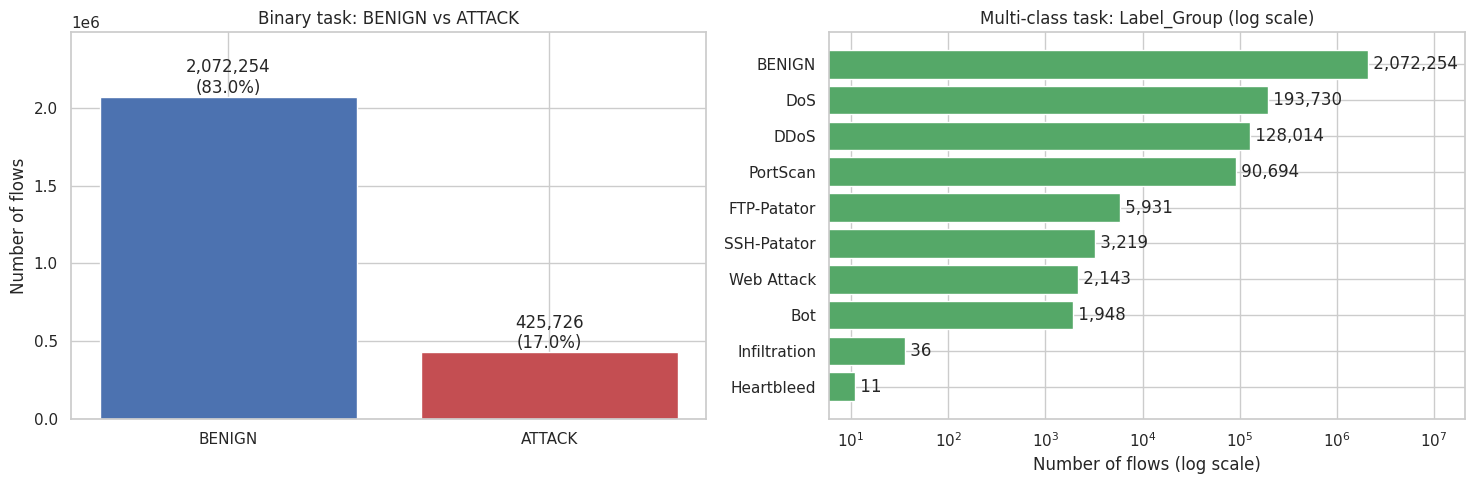

                count  percent  times_smaller_than_BENIGN
Label_Group                                              
BENIGN        2072254   82.957                        1.0
DoS            193730    7.755                       10.7
DDoS           128014    5.125                       16.2
PortScan        90694    3.631                       22.8
FTP-Patator      5931    0.237                      349.4
SSH-Patator      3219    0.129                      643.8
Web Attack       2143    0.086                      967.0
Bot              1948    0.078                     1063.8
Infiltration       36    0.001                    57562.6
Heartbleed         11    0.000                   188386.7
[saved table] /content/drive/MyDrive/network-intrusion-ml/results/tables/02_class_imbalance.csv


In [2]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Left: BENIGN vs ATTACK
bc = df["Binary"].value_counts()
axes[0].bar(bc.index, bc.values, color=["#4C72B0", "#C44E52"])
for i, v in enumerate(bc.values):
    axes[0].text(i, v, f"{v:,}\n({v/len(df):.1%})", ha="center", va="bottom")
axes[0].set_ylim(0, bc.max() * 1.2)
axes[0].set_title("Binary task: BENIGN vs ATTACK")
axes[0].set_ylabel("Number of flows")

# Right: the 10 attack/traffic categories (log scale so tiny classes are visible)
gc = df["Label_Group"].value_counts()
axes[1].barh(gc.index[::-1], gc.values[::-1], color="#55A868")
axes[1].set_xscale("log")
for i, v in enumerate(gc.values[::-1]):
    axes[1].text(v, i, f" {v:,}", va="center")
axes[1].set_xlim(right=gc.max() * 10)
axes[1].set_title("Multi-class task: Label_Group (log scale)")
axes[1].set_xlabel("Number of flows (log scale)")

save_fig("02_class_distribution")
plt.show()

# Imbalance table
imb = gc.to_frame("count")
imb["percent"] = (imb["count"] / len(df) * 100).round(3)
imb["times_smaller_than_BENIGN"] = (gc.max() / gc).round(1)
print(imb)
save_table(imb, "02_class_imbalance")

[saved figure] /content/drive/MyDrive/network-intrusion-ml/results/figures/02_feature_distributions_benign_vs_attack.png


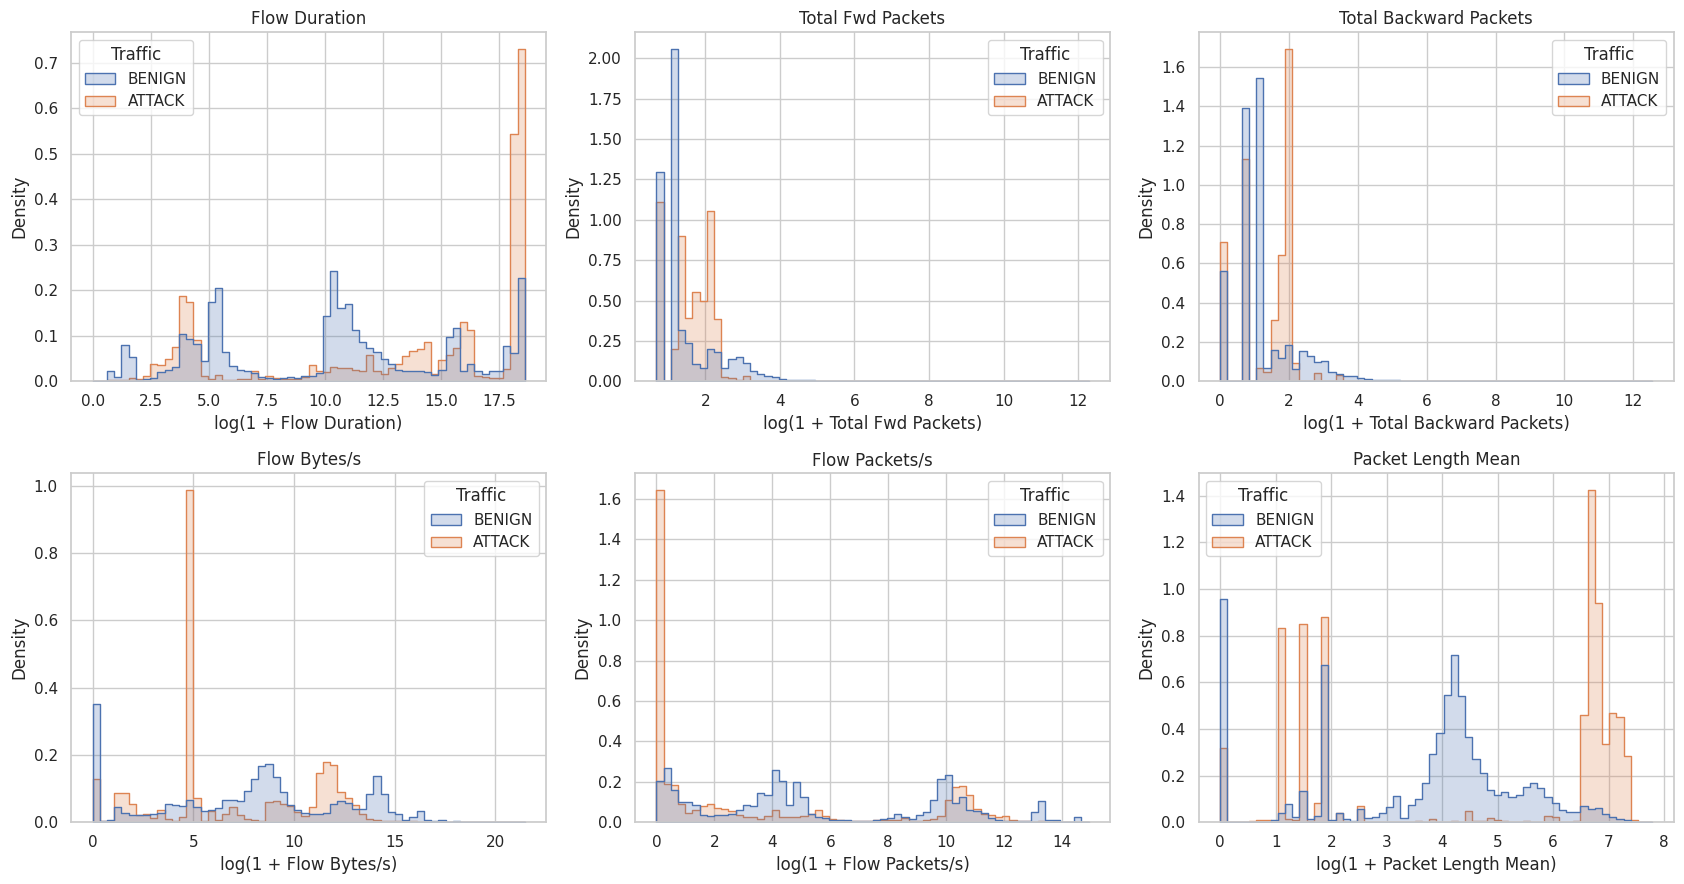

[saved table] /content/drive/MyDrive/network-intrusion-ml/results/tables/02_feature_summary_stats.csv
                               mean          std          min    median  \
Flow Duration           16737821.00  35383836.00        -13.0  51822.00   
Total Fwd Packets             10.36       797.97          1.0      2.00   
Total Backward Packets        11.66      1061.66          0.0      2.00   
Flow Bytes/s             1412812.00  26656882.00 -261000000.0   3614.66   
Flow Packets/s             47463.55    202611.58   -2000000.0     66.53   
Packet Length Mean           191.95       318.28          0.0     63.86   

                                 max  
Flow Duration           1.200000e+08  
Total Fwd Packets       2.197590e+05  
Total Backward Packets  2.919220e+05  
Flow Bytes/s            2.071000e+09  
Flow Packets/s          4.000000e+06  
Packet Length Mean      3.337140e+03  


In [3]:
sample = df.sample(200_000, random_state=RANDOM_STATE)

dist_feats = [c for c in ["Flow Duration", "Total Fwd Packets", "Total Backward Packets",
                          "Flow Bytes/s", "Flow Packets/s", "Packet Length Mean"]
              if c in df.columns]

fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for ax, col in zip(axes.ravel(), dist_feats):
    tmp = pd.DataFrame({"x": np.log1p(sample[col].clip(lower=0)), "Traffic": sample["Binary"]})
    sns.histplot(data=tmp, x="x", hue="Traffic", bins=60, stat="density",
                 common_norm=False, element="step", ax=ax)
    ax.set_xlabel(f"log(1 + {col})")
    ax.set_title(col)
save_fig("02_feature_distributions_benign_vs_attack")
plt.show()

# Mean, standard deviation, min, median, max for ALL features (project document: "Statistics")
stats = df[feature_cols].describe().T[["mean", "std", "min", "50%", "max"]]
stats = stats.rename(columns={"50%": "median"})
save_table(stats, "02_feature_summary_stats")
print(stats.loc[dist_feats].round(2))

[saved figure] /content/drive/MyDrive/network-intrusion-ml/results/figures/02_correlation_heatmap.png


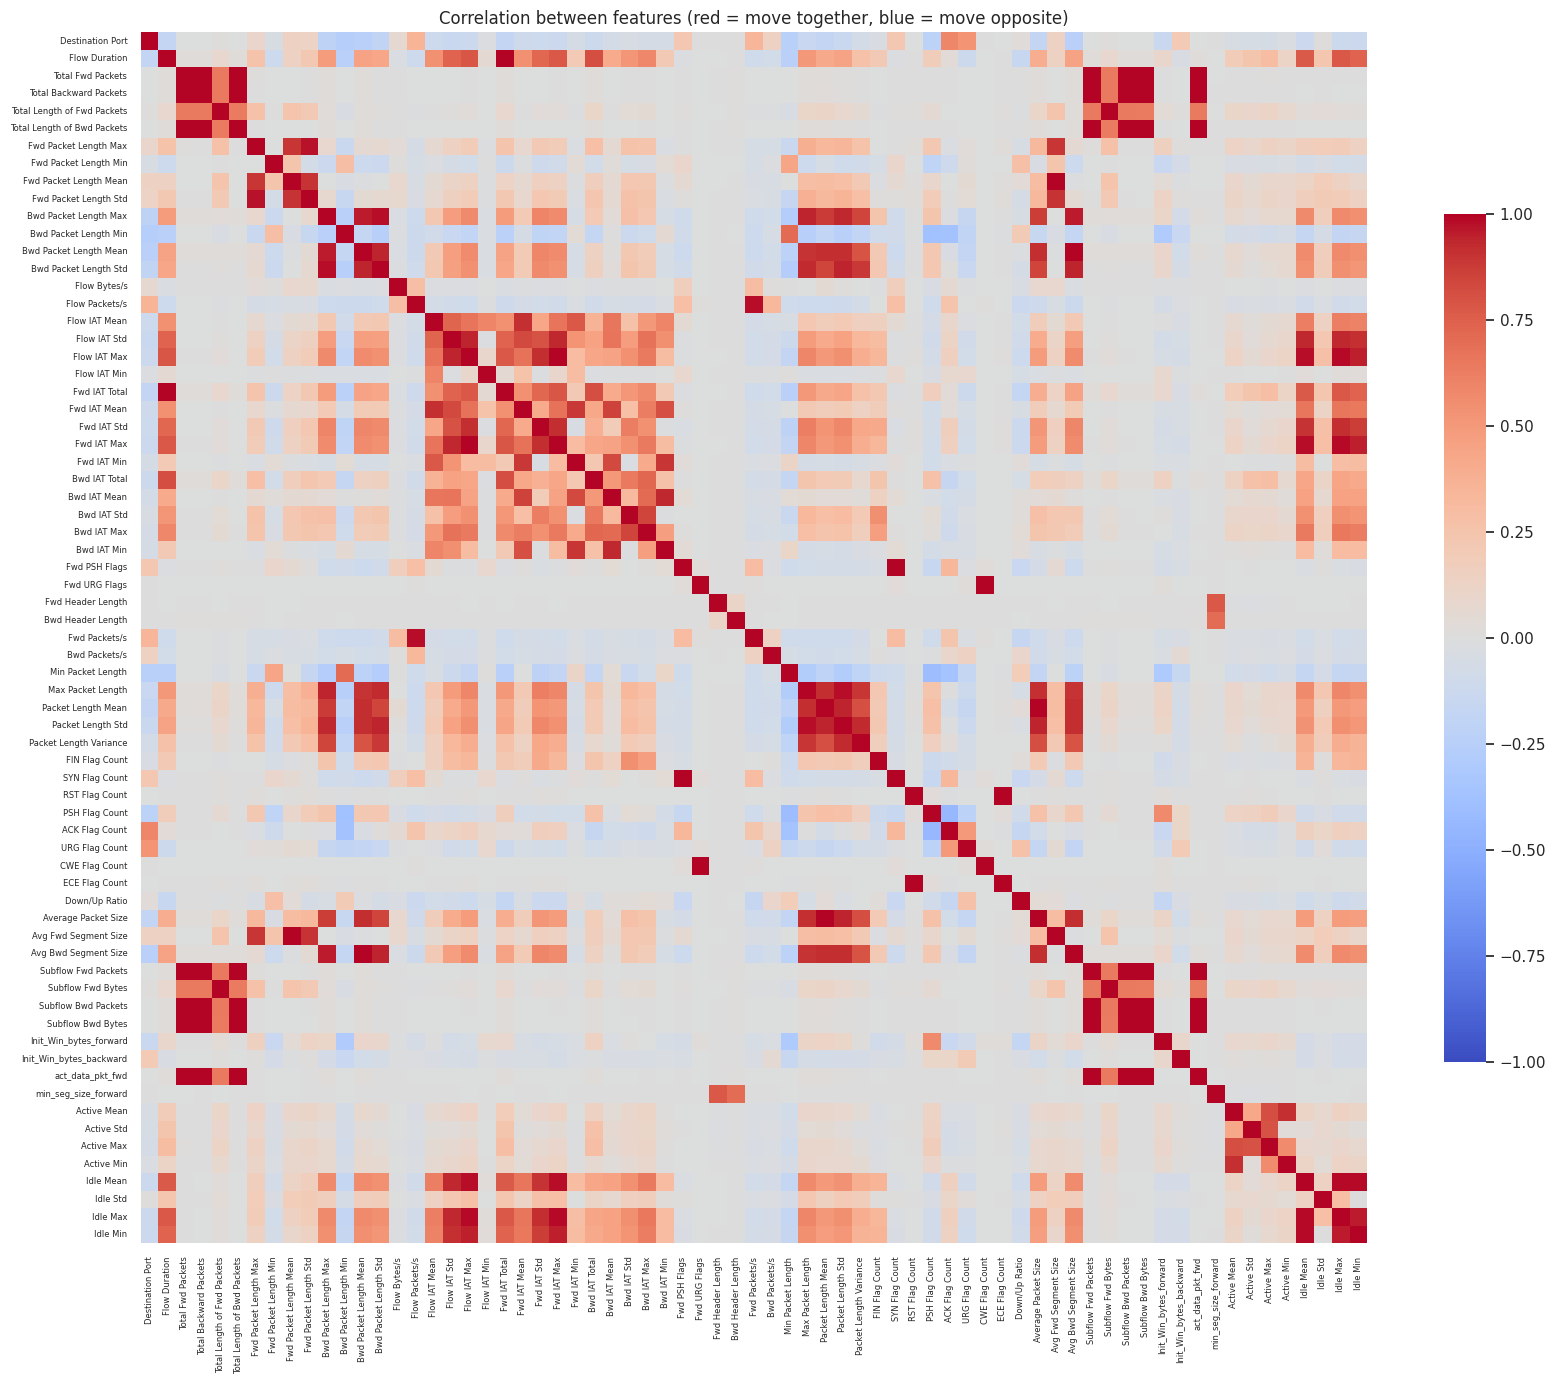

44 feature pairs with |correlation| >= 0.95
                  feature_1              feature_2  correlation
          Total Fwd Packets    Subflow Fwd Packets     1.000000
     Total Backward Packets    Subflow Bwd Packets     1.000000
     Fwd Packet Length Mean   Avg Fwd Segment Size     1.000000
Total Length of Fwd Packets      Subflow Fwd Bytes     1.000000
              Fwd URG Flags         CWE Flag Count     1.000000
     Bwd Packet Length Mean   Avg Bwd Segment Size     1.000000
             RST Flag Count         ECE Flag Count     1.000000
              Fwd PSH Flags         SYN Flag Count     1.000000
Total Length of Bwd Packets      Subflow Bwd Bytes     1.000000
        Subflow Fwd Packets    Subflow Bwd Packets     0.999761
          Total Fwd Packets    Subflow Bwd Packets     0.999761
          Total Fwd Packets Total Backward Packets     0.999761
     Total Backward Packets    Subflow Fwd Packets     0.999761
        Subflow Fwd Packets       act_data_pkt_fwd     0.998

In [4]:
sample2 = df.sample(300_000, random_state=RANDOM_STATE)
corr = sample2[feature_cols].corr()

plt.figure(figsize=(17, 14))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1,
            xticklabels=True, yticklabels=True, cbar_kws={"shrink": 0.7})
plt.xticks(fontsize=6)
plt.yticks(fontsize=6)
plt.title("Correlation between features (red = move together, blue = move opposite)")
save_fig("02_correlation_heatmap")
plt.show()

# Pairs of features that are almost copies of each other
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
pairs = upper.stack().reset_index()
pairs.columns = ["feature_1", "feature_2", "correlation"]
high = pairs[pairs["correlation"].abs() >= 0.95].sort_values("correlation", key=abs, ascending=False)
print(len(high), "feature pairs with |correlation| >= 0.95")
print(high.head(15).to_string(index=False))
save_table(high, "02_highly_correlated_pairs", index=False)

[saved figure] /content/drive/MyDrive/network-intrusion-ml/results/figures/02_top_features_vs_attack.png


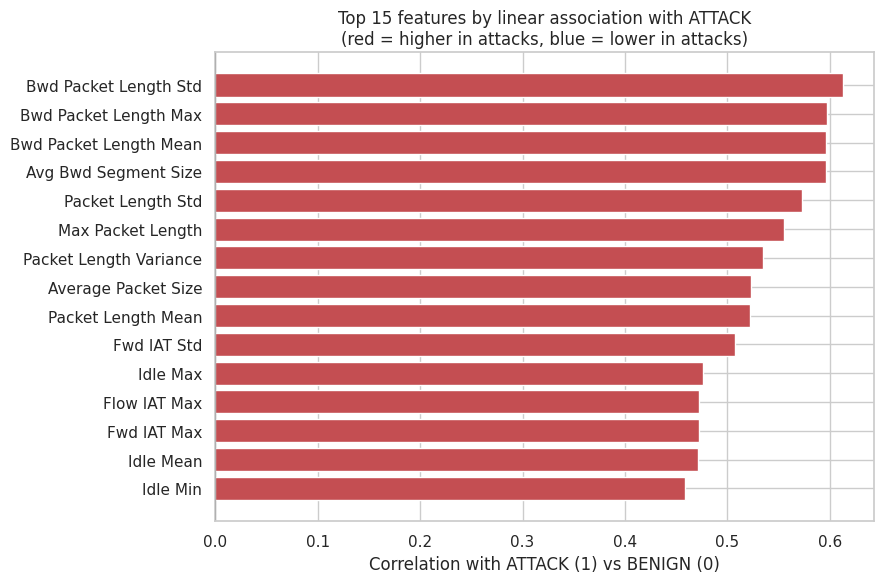

[saved table] /content/drive/MyDrive/network-intrusion-ml/results/tables/02_feature_association_with_attack.csv
Bwd Packet Length Std     0.613
Bwd Packet Length Max     0.598
Bwd Packet Length Mean    0.596
Avg Bwd Segment Size      0.596
Packet Length Std         0.573
Max Packet Length         0.555
Packet Length Variance    0.535
Average Packet Size       0.523
Packet Length Mean        0.522
Fwd IAT Std               0.508
Idle Max                  0.476
Flow IAT Max              0.473
Fwd IAT Max               0.472
Idle Mean                 0.472
Idle Min                  0.459
dtype: float64


In [5]:
is_attack = (sample2["Binary"] == "ATTACK").astype(int)
assoc = sample2[feature_cols].corrwith(is_attack).dropna()
top = assoc.abs().sort_values(ascending=False).head(15)
top_signed = assoc[top.index]

plt.figure(figsize=(9, 6))
colors = ["#C44E52" if v > 0 else "#4C72B0" for v in top_signed.values]
plt.barh(top_signed.index[::-1], top_signed.values[::-1], color=colors[::-1])
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Top 15 features by linear association with ATTACK\n(red = higher in attacks, blue = lower in attacks)")
plt.xlabel("Correlation with ATTACK (1) vs BENIGN (0)")
save_fig("02_top_features_vs_attack")
plt.show()

save_table(assoc.sort_values(key=abs, ascending=False).to_frame("correlation_with_attack"),
           "02_feature_association_with_attack")
print(top_signed.round(3))

[saved figure] /content/drive/MyDrive/network-intrusion-ml/results/figures/02_attack_category_comparison.png


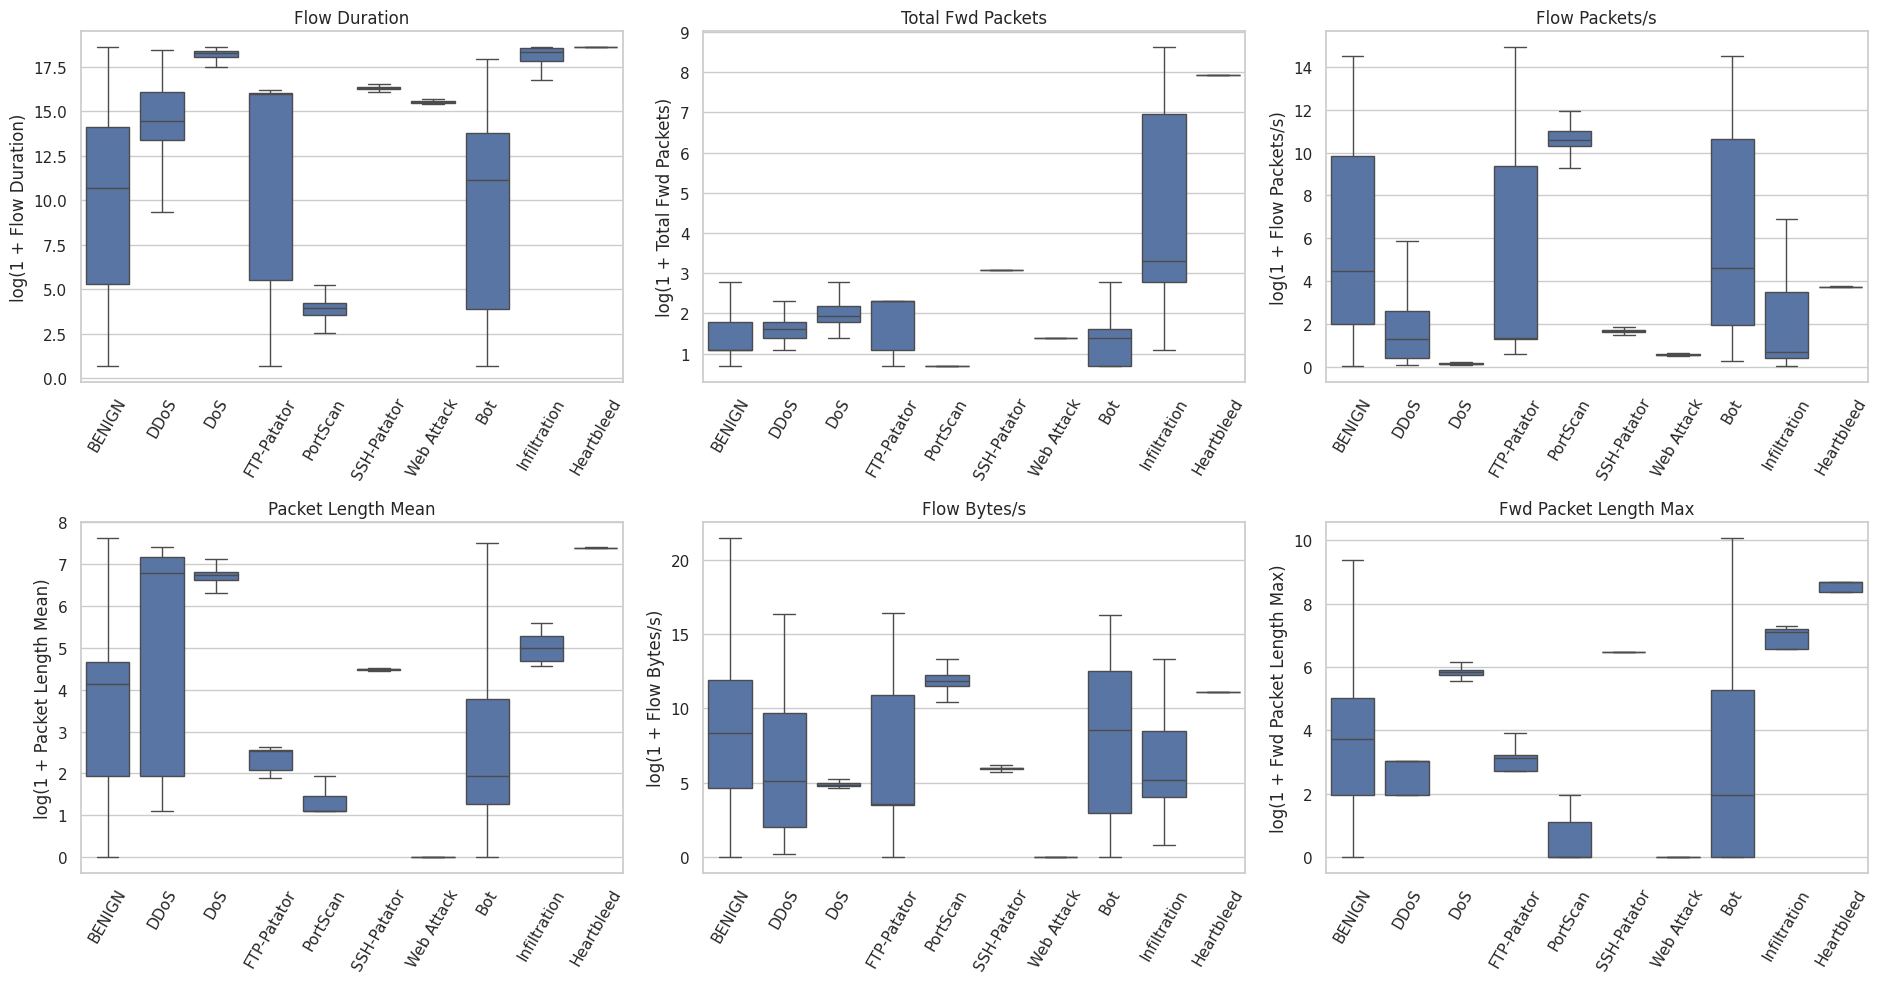

[saved table] /content/drive/MyDrive/network-intrusion-ml/results/tables/02_category_medians.csv
              Flow Duration  Total Fwd Packets  Flow Packets/s  \
Label_Group                                                      
BENIGN              42994.0                2.0       85.239998   
Bot                 71035.5                3.0      100.959999   
DDoS              1876775.5                4.0        2.680000   
DoS              85933960.0                6.0        0.150000   
FTP-Patator       8686483.0                9.0        2.760000   
Heartbleed      119261120.0             2792.0       40.840000   
Infiltration     93188868.0               26.0        1.000000   
PortScan               50.0                1.0    40000.000000   
SSH-Patator      12029788.0               21.0        4.410000   
Web Attack        5487328.0                3.0        0.740000   

              Packet Length Mean   Flow Bytes/s  Fwd Packet Length Max  
Label_Group                          

In [6]:
# Equal-size sample per category (up to 5,000 each) so small classes are visible
bal = df.sample(frac=1, random_state=RANDOM_STATE).groupby("Label_Group").head(5000)
order = bal["Label_Group"].value_counts().index.tolist()

cmp_feats = [c for c in ["Flow Duration", "Total Fwd Packets", "Flow Packets/s",
                         "Packet Length Mean", "Flow Bytes/s", "Fwd Packet Length Max"]
             if c in df.columns]

fig, axes = plt.subplots(2, 3, figsize=(19, 10))
for ax, col in zip(axes.ravel(), cmp_feats):
    tmp = pd.DataFrame({"y": np.log1p(bal[col].clip(lower=0)), "Category": bal["Label_Group"]})
    sns.boxplot(data=tmp, x="Category", y="y", order=order, showfliers=False, ax=ax)
    ax.set_ylabel(f"log(1 + {col})")
    ax.set_xlabel("")
    ax.set_title(col)
    ax.tick_params(axis="x", rotation=60)
save_fig("02_attack_category_comparison")
plt.show()

medians = bal.groupby("Label_Group")[cmp_feats].median().round(2)
save_table(medians, "02_category_medians")
print(medians)

In [7]:
print("Figures saved by this notebook:")
for f in sorted(FIG_DIR.glob("02_*")):
    print(" -", f.name)

Figures saved by this notebook:
 - 02_attack_category_comparison.png
 - 02_class_distribution.png
 - 02_correlation_heatmap.png
 - 02_feature_distributions_benign_vs_attack.png
 - 02_top_features_vs_attack.png
